In [27]:
import numpy as np
import matplotlib.pyplot as plt

In [28]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

In [29]:
x_fantoma = X_fantoma.reshape(-1)

In [30]:
def matriz_proyeccion(n, direcciones):
    res = []
    etiquetas = []

    for direccion in direcciones:                                      # Por cada dirección (α, β)
        eses = []
        for i in range(n):
            for j in range(n):
                s = direccion[0] * i + direccion[1] * j
                if s not in eses:
                    eses.append(s)

        for s in sorted(eses):
            res.append(mascara_rayo(n, direccion, s).reshape(-1))
            etiquetas.append((direccion, s))                           # Dirección y parámetro del rayo

    return np.array(res), etiquetas

In [31]:

def mascara_rayo(n, direccion, s):
  res = np.zeros((n, n))                                             # Inicializamos una matriz de ceros
  for i in range(0, n):                                              # Por cada fila
    for j in range(0, n):                                            # Por cada columna
      if direccion[0] * i + direccion[1] * j == s:                   # Vemos si está en el centro
        res[i, j] = 1                                                # Modificamos

  return res

In [32]:
n = 8

dir_7 = [(1,0), (0,1), (1,1), (1,-1), (2,1), (1,2), (3,1)]

A_7, etiquetas_7 = matriz_proyeccion(n, dir_7)
print("Dimensiones de A_7:", A_7.shape)
print("Cantidad de etiquetas:", len(etiquetas_7))

Dimensiones de A_7: (119, 64)
Cantidad de etiquetas: 119


In [33]:
np.random.seed(42)

b_7 = A_7 @ x_fantoma

z = np.random.randn(len(b_7))

escala = np.sqrt(np.mean(b_7**2))

# Valores de sigma
sigmas = [0, 0.01, 0.03, 0.06, 0.10]

# Generamos el ruido y las mediciones perturbadas
ruidos = {}
b_sigma = {}

for sigma in sigmas:
    eta = sigma * escala * z
    ruidos[sigma] = eta
    b_sigma[sigma] = b_7 + eta

### a) Función de costo, gradiente y Hessiana

La función

$$E(x)=\frac12\|A_7x-b\|^2$$

mide la mitad del error cuadrático entre las proyecciones que predice el vector $x$ y las mediciones $b$. Minimizar $E$ equivale a resolver el problema de mínimos cuadrados.

Su gradiente,

$$∇ E(x)=A_7^T(A_7x-b),$$

indica la dirección de mayor crecimiento local de la función; por eso, el método de gradiente descendente avanza en la dirección opuesta. La Hessiana es

$$H=A_7^TA_7,$$

la matriz de segundas derivadas, que describe la curvatura de esta función cuadrática. Es cuadrada, ya que actúa sobre vectores $x$ del mismo espacio. Además, es simétrica porque

$$(A_7^TA_7)^T=A_7^T(A_7^T)^T=A_7^TA_7=H.$$

La siguiente celda verifica numéricamente la simetría y comprueba dos propiedades: $E(0)=\frac12\|b\|^2$ y que el gradiente se anula en el minimizador de mínimos cuadrados $\hat{x}$.

In [34]:
sigma = 0.06
b = b_sigma[sigma]

def E(x):
    return 0.5 * np.linalg.norm(A_7 @ x - b) ** 2

def grad_E(x):
    return A_7.T @ (A_7 @ x - b)

H = A_7.T @ A_7
x_hat = np.linalg.lstsq(A_7, b, rcond=None)[0]

print("Dimensiones de H:", H.shape)
print("H es simétrica:", np.allclose(H, H.T))
print(f"E(0) = {E(np.zeros(A_7.shape[1])):.10f}")
print(f"0.5 * ||b||^2 = {0.5 * np.linalg.norm(b)**2:.10f}")
print("¿Coinciden?", np.allclose(E(np.zeros(A_7.shape[1])), 0.5 * np.linalg.norm(b)**2))
print(f"||grad_E(x_hat)|| = {np.linalg.norm(grad_E(x_hat)):.3e}")

Dimensiones de H: (64, 64)
H es simétrica: True
E(0) = 70.6876012259
0.5 * ||b||^2 = 70.6876012259
¿Coinciden? True
||grad_E(x_hat)|| = 3.955e-14


La igualdad $H^T=H$ se deduce algebraicamente de $H=A_7^TA_7$ y también queda confirmada por el chequeo numérico. La norma del gradiente en $\hat{x}$ es prácticamente cero, como corresponde a un minimizador de mínimos cuadrados.

### b) Gradiente descendente

In [35]:
def gradiente_descendente(x0, alpha, n_iter):
    x = x0.copy()
    costos = []
    normas_grad = []

    for t in range(n_iter):
        g = grad_E(x)               # gradiente en el punto actual
        costos.append(E(x))             # costo en el punto actual
        normas_grad.append(np.linalg.norm(g))  # norma del gradiente
        x = x - alpha * g              # paso de gradiente descendiente

    return x, costos, normas_grad

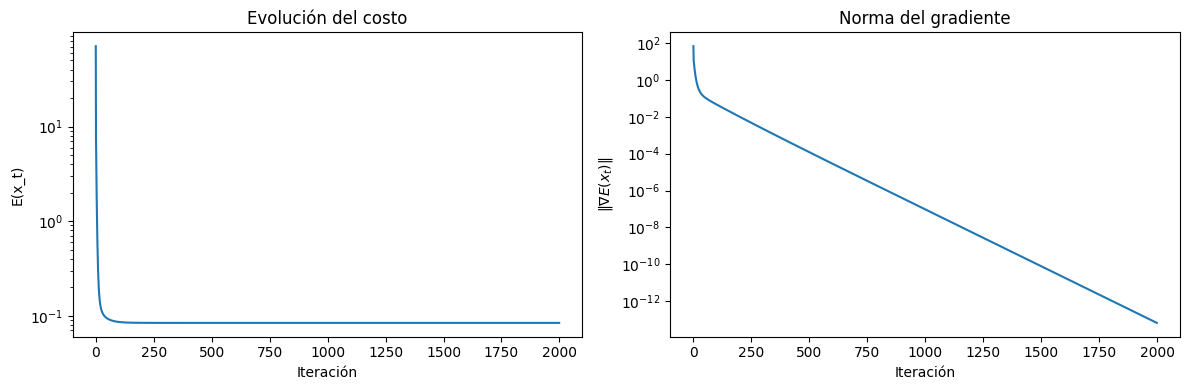

Tasa de aprendizaje: alpha = 0.0274248
Costo inicial: 70.687601
Costo final registrado: 0.084102
Norma inicial del gradiente: 66.361973
Norma final registrada: 6.731e-14


In [36]:
# Ejecutamos gradiente descendente y registramos costo y norma del gradiente.
mu = np.linalg.eigvalsh(H)
mu_max = mu[-1]
alpha_b = 1 / mu_max
x_gd_b, costos_b, normas_grad_b = gradiente_descendente(
    np.zeros(A_7.shape[1]), alpha_b, 2000
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(costos_b)
axes[0].set_title("Evolución del costo")
axes[0].set_xlabel("Iteración")
axes[0].set_ylabel("E(x_t)")

axes[1].semilogy(np.maximum(normas_grad_b, np.finfo(float).tiny))
axes[1].set_title("Norma del gradiente")
axes[1].set_xlabel("Iteración")
axes[1].set_ylabel(r"$\|\nabla E(x_t)\|$")

plt.tight_layout()
plt.show()

print(f"Tasa de aprendizaje: alpha = {alpha_b:.6g}")
print(f"Costo inicial: {costos_b[0]:.6f}")
print(f"Costo final registrado: {costos_b[-1]:.6f}")
print(f"Norma inicial del gradiente: {normas_grad_b[0]:.6f}")
print(f"Norma final registrada: {normas_grad_b[-1]:.3e}")

El costo baja de 70.69 a 0.0841 (el mínimo, que no es 0 por el ruido) y el gradiente cae hasta ~10⁻¹³, lo que indica que se llegó al minimizador.

### c) Elección de la tasa de aprendizaje

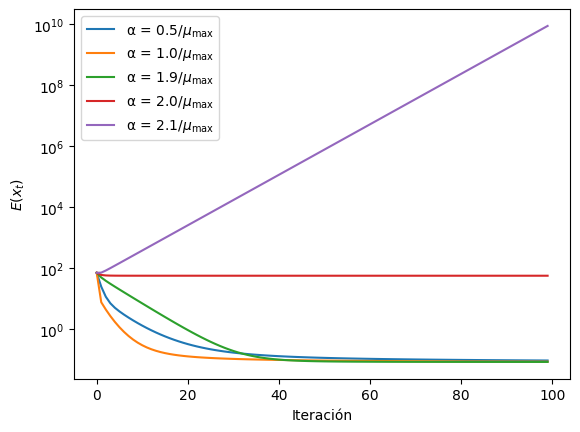

In [37]:
mu = np.linalg.eigvalsh(H)
mu_max = mu[-1]   ## mu es un array con los autovalores de H ordenados de manera creciente. la posicion -1 es el valor mas alto por ende.

factores = [0.5, 1.0, 1.9, 2.0, 2.1]

plt.figure()
for f in factores:
    alpha = f / mu_max
    _, costos, _ = gradiente_descendente(np.zeros(H.shape[0]), alpha, 100)
    plt.semilogy(costos, label=rf"α = {f}/$\mu_{{\max}}$")

plt.xlabel("Iteración")
plt.ylabel("$E(x_t)$")
plt.legend()
plt.show()

En el gráfico se compara la evolución del costo para distintas tasas de aprendizaje. Para analizar los resultados, consideramos una función cuadrática con Hessiana $H=A_7^T A_7$, donde $A_7$ tiene rango completo. Por lo tanto, $H$ es definida positiva y todos sus autovalores son positivos.

Sea $\hat{x}$ el punto mínimo y definamos el error como $e_t=x_t-\hat{x}$. Como $\nabla E(\hat{x})=0$ y el gradiente de la función de costo es $\nabla E(x)=Hx-A_7^T b_\sigma$, se tiene:

$$
\nabla E(x_t)=\nabla E(x_t)-\nabla E(\hat{x})
=H(x_t-\hat{x})=He_t.
$$

Reemplazando en la actualización del gradiente descendente:

$$
x_{t+1}=x_t-\alpha\nabla E(x_t),
$$

obtenemos:

$$
e_{t+1}=x_{t+1}-\hat{x}
=(I-\alpha H)e_t.
$$

Si expresamos el error en la base de autovectores de $H$, cada componente asociada a un autovalor $\mu_i$ se multiplica en cada iteración por el factor $1-\alpha\mu_i$. Para que todas las componentes converjan a cero, debe cumplirse:

$$
|1-\alpha\mu_i|<1.
$$

Esta desigualdad equivale a $0<\alpha\mu_i<2$. Como todos los autovalores son positivos, la condición más exigente corresponde al mayor autovalor, $\mu_{\max}$. Por lo tanto, el intervalo de convergencia es:

$$
0<\alpha<\frac{2}{\mu_{\max}}.
$$

Para $\alpha=0.5/\mu_{\max}$, el costo disminuye progresivamente y el método converge con una velocidad moderada.

Para $\alpha=1.0/\mu_{\max}$, el costo disminuye rápidamente al principio. Sin embargo, la velocidad de convergencia depende de todas las componentes del error, por lo que no se puede afirmar que esta tasa sea siempre la más rápida.

Para $\alpha=1.9/\mu_{\max}$, el factor correspondiente al mayor autovalor es $1-1.9=-0.9$. Esto significa que dicha componente cambia de signo en cada iteración y su magnitud se reduce solamente un 10 % por paso. Por eso, si esta componente domina inicialmente, el costo puede disminuir más lentamente al principio, aunque luego la curva puede superar a la correspondiente a $\alpha=0.5/\mu_{\max}$.

Para $\alpha=2.0/\mu_{\max}$, la componente asociada al mayor autovalor se multiplica por:

$$
1-\alpha\mu_{\max}=1-2=-1.
$$

Su magnitud no disminuye, sino que cambia de signo en cada iteración. Las demás componentes pueden reducirse, lo que explica que el costo baje inicialmente y luego quede prácticamente constante por encima del mínimo. En este caso límite, no se garantiza la convergencia.

Finalmente, para $\alpha=2.1/\mu_{\max}$, el factor correspondiente al mayor autovalor es:

$$
1-\alpha\mu_{\max}=1-2.1=-1.1.
$$

Por lo tanto, la magnitud de esa componente del error crece por un factor de $1.1$ en cada iteración. Como el costo cuadrático depende del cuadrado del error, la contribución de esa componente al costo crece por un factor de $1.1^2=1.21$ por iteración. Esto explica el crecimiento exponencial observado en el gráfico y la divergencia del método.

En conclusión, para una función cuadrática con Hessiana definida positiva, el método converge cuando $0<\alpha<2/\mu_{\max}$. En el límite $\alpha=2/\mu_{\max}$, la convergencia no está garantizada, mientras que para $\alpha>2/\mu_{\max}$ el método se vuelve inestable y diverge.

d)

In [38]:
def newton(x0, n_iter):
    x = x0.copy()
    costos = []
    normas_grad = []

    for _ in range(n_iter):
        g = grad_E(x)                          # gradiente en el punto actual
        costos.append(E(x))                    # costo en el punto actual
        normas_grad.append(np.linalg.norm(g))
        p = np.linalg.solve(H, g)                          # resolver H p = g con np.linalg.solve
        x = x - p                          # paso de Newton

    return x, costos, normas_grad

In [39]:
x1, costos_n, grads_n = newton(np.zeros(A_7.shape[1]), 1)
print("Distancia entre Newton y lstsq:", f"{np.linalg.norm(x1 - x_hat):.3e}")

x3, costos_n3, grads_n3 = newton(np.zeros(A_7.shape[1]), 3)
print("Costos registrados por Newton:", [float(v) for v in costos_n3])
print("Normas del gradiente registradas por Newton:", [float(v) for v in grads_n3])

Distancia entre Newton y lstsq: 7.147e-15
Costos registrados por Newton: [70.68760122588972, 0.08410238184800674, 0.08410238184800667]
Normas del gradiente registradas por Newton: [66.36197327563552, 1.881622976626353e-14, 4.4347363400111464e-15]


### Método de Newton para una función cuadrática

El método de Newton actualiza la solución mediante:

$$
x_1=x_0-H^{-1}\nabla E(x_0).
$$

Como el gradiente de la función de costo es

$$
\nabla E(x_0)=Hx_0-A_7^T b_\sigma,
$$

reemplazamos esta expresión en la actualización:

$$
x_1=x_0-H^{-1}(Hx_0-A_7^T b_\sigma).
$$

Distribuyendo $H^{-1}$, obtenemos:

$$
x_1=x_0-H^{-1}Hx_0+H^{-1}A_7^T b_\sigma.
$$

Como $H^{-1}H=I$, los dos primeros términos se cancelan y queda:

$$
\boxed{x_1=H^{-1}A_7^T b_\sigma}.
$$

Esta expresión no depende de $x_0$, por lo que el método llega al mismo punto después de una única iteración, independientemente del punto inicial.

Además, multiplicando la expresión anterior por $H$ a izquierda, obtenemos:

$$
Hx_1=HH^{-1}A_7^T b_\sigma=A_7^T b_\sigma.
$$

Como $H=A_7^T A_7$, resulta:

$$
\boxed{A_7^T A_7x_1=A_7^T b_\sigma}.
$$

Por lo tanto, $x_1$ satisface las ecuaciones normales y es el minimizador de la función de costo cuadrática.

Esto ocurre porque el método de Newton utiliza una aproximación de Taylor de segundo orden de la función de costo. Como en este caso la función ya es cuadrática, dicha aproximación es exacta. Además, su Hessiana es constante, por lo que el método alcanza el mínimo en una única iteración, siempre que $H$ sea invertible.

La invertibilidad está garantizada porque $A_7$ tiene rango completo y, por lo tanto, $H=A_7^T A_7$ es definida positiva.

Si la función no fuera cuadrática, la aproximación de Taylor de segundo orden no sería exacta en general y Newton necesitaría varias iteraciones para converger.

### Verificación numérica

Los resultados obtenidos desde $x_0=0$ confirman lo demostrado teóricamente:

- La distancia entre la solución obtenida y el minimizador es aproximadamente $\|x_1-\hat{x}\|\approx 7\cdot 10^{-15}$, un valor prácticamente nulo debido a los errores de redondeo numérico.
- El costo disminuye de $70.69$ a $0.0841$, coincidiendo este último valor con $\frac{1}{2}\|r\|^2$ obtenido en el ejercicio 6.
- La norma del gradiente disminuye de $66.4$ a aproximadamente $10^{-14}$, lo que confirma que se alcanzó un punto estacionario.

En conclusión, los resultados numéricos verifican que Newton encuentra el minimizador de esta función cuadrática en una única iteración desde $x_0=0$, tal como predice la demostración, que es válida para cualquier punto inicial.

e)

In [40]:
x_gd, costos_gd, grads_gd = gradiente_descendente(np.zeros(64), 1 / mu_max, 2000)

In [41]:
metodos = {
    "lstsq": x_hat,
    "Newton": x1,
    "Grad. desc.": x_gd
}

iteraciones = {
    "lstsq": 0,                 # resolución directa, sin iteraciones
    "Newton": 1,                # una iteración basta para esta función cuadrática
    "Grad. desc.": len(costos_gd)
}

print(f"{'Método':12s} | {'Iter.':>5s} | {'||x - x_hat||':>14s} | {'Error relativo':>14s} | {'||A_7 x - b_sigma||':>19s}")
print("-" * 78)

for nombre, x_rec in metodos.items():
    dist = np.linalg.norm(x_rec - x_hat)
    err_rel = np.linalg.norm(x_rec - x_fantoma) / np.linalg.norm(x_fantoma)
    res = np.linalg.norm(A_7 @ x_rec - b)

    print(f"{nombre:12s} | {iteraciones[nombre]:5d} | {dist:14.2e} | {err_rel:14.6f} | {res:19.6f}")

Método       | Iter. |  ||x - x_hat|| | Error relativo | ||A_7 x - b_sigma||
------------------------------------------------------------------------------
lstsq        |     0 |       0.00e+00 |       0.128928 |            0.410128
Newton       |     1 |       7.15e-15 |       0.128928 |            0.410128
Grad. desc.  |  2000 |       1.29e-13 |       0.128928 |            0.410128


/tmp/ipykernel_1065/1075129080.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


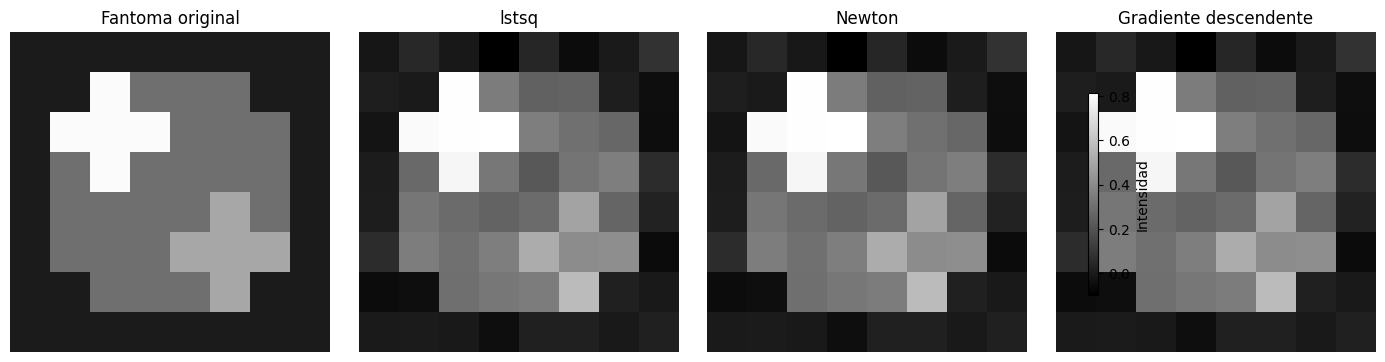

/tmp/ipykernel_1065/1075129080.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


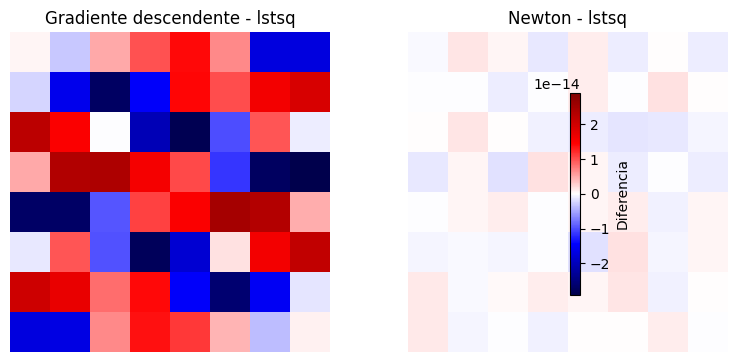

In [42]:
# Comparación visual de las reconstrucciones
imagenes = [
    ("Fantoma original", x_fantoma),
    ("lstsq", x_hat),
    ("Newton", x1),
    ("Gradiente descendente", x_gd)
]

n_img = X_fantoma.shape[0]
vmin = min(np.min(img) for _, img in imagenes)
vmax = max(np.max(img) for _, img in imagenes)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

for ax, (titulo, img) in zip(axes, imagenes):
    im = ax.imshow(np.asarray(img).reshape(n_img, n_img),
                   cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(titulo)
    ax.axis("off")

fig.colorbar(im, ax=axes, shrink=0.75, label="Intensidad")
plt.tight_layout()
plt.show()

# Diferencias respecto de la solución de lstsq
diferencias = [
    ("Gradiente descendente - lstsq", x_gd - x_hat),
    ("Newton - lstsq", x1 - x_hat)
]

lim = max(np.max(np.abs(d)) for _, d in diferencias)
if lim == 0:
    lim = 1e-15  # evita una escala nula si las diferencias fueran exactamente cero

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, (titulo, d) in zip(axes, diferencias):
    im_diff = ax.imshow(d.reshape(n_img, n_img), cmap="seismic",
                        vmin=-lim, vmax=lim)
    ax.set_title(titulo)
    ax.axis("off")

fig.colorbar(im_diff, ax=axes, shrink=0.75, label="Diferencia")
plt.tight_layout()
plt.show()

### Análisis de los resultados

Los tres métodos resuelven el mismo problema de mínimos cuadrados y obtienen prácticamente la misma reconstrucción. La distancia entre Newton y `lstsq` es del orden de $10^{-15}$, mientras que para gradiente descendente es del orden de $10^{-13}$. Estas diferencias son despreciables y se deben a la precisión finita de los cálculos numéricos.

El error relativo respecto del fantoma es aproximadamente $0.1289$ para los tres métodos, coincidiendo con el resultado del ejercicio 6 para $\sigma=0.06$. Este error no es cero porque las mediciones contienen ruido: los métodos encuentran la solución de mínimos cuadrados para los datos perturbados, no necesariamente el fantoma original.

La norma del residuo también coincide en los tres casos y vale aproximadamente $0.4101$. Esto confirma que las reconstrucciones ajustan los mismos datos observados.

En cuanto a los parámetros, gradiente descendente requiere elegir la tasa de aprendizaje $\alpha$ y la cantidad de iteraciones. En este caso se usó $\alpha=1/\mu_{\max}$ y 2000 iteraciones. Newton no requiere elegir una tasa de aprendizaje en esta implementación y, como la función es cuadrática con Hessiana invertible, alcanza el mínimo en una iteración. `lstsq` resuelve directamente el problema sin realizar iteraciones de optimización.

Para este problema pequeño, `lstsq` es una opción práctica y estable; Newton también es muy rápido si se aprovecha la estructura cuadrática. Para el problema del ejercicio 10, con $n^2=16384$, formar y almacenar una Hessiana densa de tamaño $16384\times16384$ sería costoso. En dimensiones grandes conviene evitar esa matriz explícita y considerar métodos iterativos que utilicen productos matriz-vector, según la estructura de la matriz de proyección.